# Lab 2 Homework solutions

## Fresh databases

In [1]:
import subprocess
import time
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.ticker import PercentFormatter

In [2]:

DATA = Path("data/homework")
DATA.mkdir(parents=True, exist_ok=True)
SERVICE_YEARS = list(range(2019, 2026))
DISRUPTION_YEARS = list(range(2011, 2024))
PG_CONTAINER = "lab02-homework-postgres"
PG_PORT = 5434
DB_PATH = DATA / "homework.duckdb"

plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True})

# Ensure fresh database for each run
for old_file in (
    DB_PATH,
    Path(str(DB_PATH) + ".wal"),
):
    if old_file.exists():
        old_file.unlink()

db = duckdb.connect(str(DB_PATH))
db.execute("SET memory_limit = '1GB'")
db.execute("SET threads = 2")
db.execute("SET preserve_insertion_order = false")
db.execute("SET TimeZone = 'Europe/Amsterdam'")


def sql_value(value):
    return "'" + str(value).replace("'", "''") + "'"


def query(sql):
    return db.sql(sql).df()


subprocess.run([
    "docker", "run", "--detach", "--rm", "--name", PG_CONTAINER,
    "-e", "POSTGRES_PASSWORD=postgres",
    "-p", f"127.0.0.1:{PG_PORT}:5432", "postgres:17",
], check=True, capture_output=True)
for attempt in range(60):
    ready = subprocess.run([
        "docker", "exec", PG_CONTAINER, "pg_isready", "-h", "127.0.0.1", "-U", "postgres",
    ], capture_output=True, check=False)
    if ready.returncode == 0:
        break
    time.sleep(1)
else:
    raise RuntimeError("Postgres did not start. Check Docker logs.")
print("Fresh DuckDB and Postgres are ready.")

Fresh DuckDB and Postgres are ready.


## 1. Download data

In [3]:
BASE = "https://opendata.rijdendetreinen.nl/public"


def download(folder, filename):
    path = DATA / filename
    if not path.exists():
        print("Downloading", filename, flush=True)
        temporary = path.with_suffix(path.suffix + ".part")
        subprocess.run([
            "curl", "--fail", "--location", "--retry", "3",
            "--output", str(temporary), f"{BASE}/{folder}/{filename}",
        ], check=True)
        temporary.replace(path)
    return str(path)


stations_file = download("stations", "stations-2023-09.csv")
distances_file = download("tariff-distances", "tariff-distances-2022-01.csv")
disruption_files = [
    download("disruptions", f"disruptions-{year}.csv")
    for year in DISRUPTION_YEARS
]
service_files = [
    download("services", f"services-{year}.csv.gz")
    for year in SERVICE_YEARS
]
print("Service years:", SERVICE_YEARS)
print("Disruption years:", DISRUPTION_YEARS)

Service years: [2019, 2020, 2021, 2022, 2023, 2024, 2025]
Disruption years: [2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]


## 2. Stations in DuckDB

In [4]:
db.sql(f"""
    CREATE TABLE stations AS
    SELECT * REPLACE (upper(code) AS code)
    FROM read_csv({sql_value(stations_file)})
""")
display(query("SELECT * FROM stations LIMIT 5"))

,id,code,uic,name_short,name_medium,name_long,slug,country,type,geo_lat,geo_lng
0,266,HT,8400319,Den Bosch,'s-Hertogenbosch,'s-Hertogenbosch,s-hertogenbosch,NL,knooppuntIntercitystation,51.690480,5.293620
1,269,HTO,8400320,Dn Bosch O,'s-Hertogenb. O.,'s-Hertogenbosch Oost,s-hertogenbosch-oost,NL,stoptreinstation,51.700554,5.318333
2,227,HDE,8400388,'t Harde,'t Harde,'t Harde,t-harde,NL,stoptreinstation,52.409168,5.893611
3,8,AHBF,8015345,Aachen,Aachen Hbf,Aachen Hbf,aachen-hbf,D,knooppuntIntercitystation,50.767800,6.091499
4,818,AW,8015199,Aachen W,Aachen West,Aachen West,aachen-west,D,stoptreinstation,50.780360,6.070715


## 3. Distance tables

`XXX` means the same station & `UNPIVOT` turns the matrix into station pairs

In [5]:
db.sql(f"""
    CREATE TABLE distances AS
    SELECT * FROM read_csv({sql_value(distances_file)}, nullstr = 'XXX')
""")
db.sql("""
    CREATE TABLE distances_long AS
    UNPIVOT distances
    ON COLUMNS (* EXCLUDE Station)
    INTO NAME other_station VALUE distance
""")
display(query("SELECT * FROM distances_long LIMIT 5"))

,Station,other_station,distance
0,AC,AH,82
1,AC,AHP,83
2,AC,AHPR,85
3,AC,AHZ,90
4,AC,AKL,71


## 4. Disruptions in Postgres

DuckDB writes the CSV rows to Postgres + DuckDB view to read the data

In [6]:
db.execute("INSTALL postgres")
db.execute("LOAD postgres")
pg_connection = (
    f"host=127.0.0.1 port={PG_PORT} "
    "dbname=postgres user=postgres password=postgres"
)
db.sql(f"ATTACH {sql_value(pg_connection)} AS pg (TYPE postgres)")
db.sql(f"""
    CREATE TABLE pg.public.disruptions AS
    SELECT * FROM read_csv({disruption_files!r}, union_by_name = true)
""")
db.sql("""
    CREATE VIEW disruptions AS
    SELECT * FROM pg.public.disruptions
""")
display(query("DESCRIBE disruptions"))
display(query("SELECT count(*) AS disruption_events FROM disruptions"))

,column_name,column_type,null,key,default,extra
0,rdt_id,BIGINT,YES,None,None,None
1,ns_lines,VARCHAR,YES,None,None,None
2,rdt_lines,VARCHAR,YES,None,None,None
3,rdt_lines_id,VARCHAR,YES,None,None,None
4,rdt_station_names,VARCHAR,YES,None,None,None
5,rdt_station_codes,VARCHAR,YES,None,None,None
6,cause_nl,VARCHAR,YES,None,None,None
7,cause_en,VARCHAR,YES,None,None,None
8,statistical_cause_nl,VARCHAR,YES,None,None,None
9,statistical_cause_en,VARCHAR,YES,None,None,None


,disruption_events
0,49900


## 5. Services: CSV → one Parquet

DuckDB reads the compressed CSV files directly. Explicit types avoid guessing errors across years. Parquet uses ZSTD compression.

In [7]:
parquet_file = str(DATA / "services-2019-2025.parquet")

# Refresh pq file if already exists
if Path(parquet_file).exists():
    Path(parquet_file).unlink()

duckdb.execute(
    f"""
    COPY (
        SELECT * FROM read_csv($files)
    )
    TO {sql_value(parquet_file)}
    (FORMAT PARQUET, COMPRESSION ZSTD)
    """,
    {"files": [str(f) for f in service_files]},
)

print(f"Parquet size: {Path(parquet_file).stat().st_size / 1024**2:.2f} MiB")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Parquet size: 1044.03 MiB


In [8]:
db.execute(f"""
    CREATE TABLE services AS
    SELECT *
    FROM read_parquet({sql_value(parquet_file)})
""")

display(query("""
    SELECT count(*) AS total_stop_records
    FROM services
"""))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_stop_records
0,152176324


## 6. Helper table each service once

In [9]:
db.execute("""
    CREATE TABLE service_summary AS
    SELECT "Service:RDT-ID" AS service_id,
           min("Service:Date") AS service_date,
           bool_or("Service:Completely cancelled") AS completely_cancelled,
           bool_or("Service:Partly cancelled") AS partly_cancelled,
           max("Service:Maximum delay") AS maximum_delay,
           max("Stop:Station code") FILTER (
               WHERE "Stop:Arrival time" IS NULL
                 AND "Stop:Departure time" IS NOT NULL
           ) AS start_station_code,
           max("Stop:Station code") FILTER (
               WHERE "Stop:Departure time" IS NULL
                 AND "Stop:Arrival time" IS NOT NULL
           ) AS end_station_code
    FROM services
    GROUP BY "Service:RDT-ID"
""")
display(query("""
    SELECT count(*) AS services,
           count(*) FILTER (WHERE start_station_code IS NULL) AS missing_start,
           count(*) FILTER (WHERE end_station_code IS NULL) AS missing_end
    FROM service_summary
"""))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,services,missing_start,missing_end
0,16750696,49032,166878


In [10]:
display(query("""
    DESCRIBE services
"""))

,column_name,column_type,null,key,default,extra
0,Service:RDT-ID,BIGINT,YES,None,None,None
1,Service:Date,DATE,YES,None,None,None
2,Service:Type,VARCHAR,YES,None,None,None
3,Service:Company,VARCHAR,YES,None,None,None
4,Service:Train number,BIGINT,YES,None,None,None
5,Service:Completely cancelled,BOOLEAN,YES,None,None,None
6,Service:Partly cancelled,BOOLEAN,YES,None,None,None
7,Service:Maximum delay,BIGINT,YES,None,None,None
8,Stop:RDT-ID,BIGINT,YES,None,None,None
9,Stop:Station code,VARCHAR,YES,None,None,None


In [11]:
display(query("""
    DESCRIBE service_summary
"""))

,column_name,column_type,null,key,default,extra
0,service_id,BIGINT,YES,None,None,None
1,service_date,DATE,YES,None,None,None
2,completely_cancelled,BOOLEAN,YES,None,None,None
3,partly_cancelled,BOOLEAN,YES,None,None,None
4,maximum_delay,BIGINT,YES,None,None,None
5,start_station_code,VARCHAR,YES,None,None,None
6,end_station_code,VARCHAR,YES,None,None,None


## 7.1. How many trains departed from Amsterdam Central station overall?

In [12]:
display(query("""
    SELECT count(DISTINCT "Service:RDT-ID") AS trains_departed
    FROM services
    WHERE "Stop:Station code" = 'ASD'
      AND "Stop:Departure time" IS NOT NULL
      AND "Stop:Departure cancelled" = false
      AND "Service:Completely cancelled" = false
"""))

,trains_departed
0,1799103


## 7.2. Calculate the average arrival delay of different service types (Service:Type). Order results descending by average delay.

In [13]:
display(query("""
    SELECT "Service:Type" AS service_type,
           avg("Stop:Arrival delay") AS average_delay_minutes
    FROM services
    WHERE "Stop:Arrival time" IS NOT NULL
      AND "Stop:Arrival cancelled" = false
    GROUP BY "Service:Type"
    ORDER BY average_delay_minutes DESC NULLS LAST
"""))

,service_type,average_delay_minutes
0,Alpen Express,27.826625
1,Krokus Express,18.304348
2,European Sleeper,14.586861
3,Nightjet,9.899678
4,ICE,7.980200
5,Eurostar,7.529096
6,ICE International,5.821847
7,Thalys,5.707679
8,Int. Trein,4.184951
9,Nachttrein,4.056489


## 7.3 What was the most common disruption cause in different years?

In [14]:
display(query("""
    WITH causes AS (
        SELECT year(start_time) AS year, cause_en AS cause,
               count(*) AS events
        FROM disruptions
        WHERE nullif(trim(cause_en), '') IS NOT NULL
        GROUP BY year, cause_en
    )
    SELECT year, cause, events
    FROM causes
    QUALIFY dense_rank() OVER (PARTITION BY year ORDER BY events DESC) = 1
    ORDER BY year, cause
"""))

,year,cause,events
0,2011,broken down train,237
1,2012,points failure,266
2,2013,points failure,343
3,2014,broken down train,307
4,2015,broken down train,487
5,2016,broken down train,569
6,2017,broken down train,1313
7,2018,broken down train,2080
8,2019,broken down train,2314
9,2020,broken down train,1615


## 7.4. How many trains started their overall service in any Amsterdam station?

In [15]:
display(query("""
    SELECT count(*) AS services_starting_in_amsterdam
    FROM service_summary s
    JOIN stations st ON s.start_station_code = st.code
    WHERE st.country = 'NL'
      AND st.name_long ILIKE 'Amsterdam%'
"""))

,services_starting_in_amsterdam
0,1256527


## 7.5. What fraction of services was run to final destinations outside the Netherlands?

In [16]:
display(query("""
    SELECT count(*) AS all_services,
           count(*) FILTER (WHERE st.country <> 'NL') AS foreign_destinations,
           count(*) FILTER (WHERE st.country IS NULL) AS unknown_destinations,
           count(*) FILTER (WHERE st.country <> 'NL')::DOUBLE
               / nullif(count(*), 0) AS fraction_abroad
    FROM service_summary s
    LEFT JOIN stations st ON s.end_station_code = st.code
"""))

,all_services,foreign_destinations,unknown_destinations,fraction_abroad
0,16750696,621410,184675,0.037098


## 7.6. What is the largest distance between stations in the Netherlands (code NL)?

In [17]:
display(query("""
    SELECT a.name_long AS start_station, b.name_long AS end_station,
           d.distance AS distance_km
    FROM distances_long d
    JOIN stations a ON d.Station = a.code
    JOIN stations b ON d.other_station = b.code
    WHERE a.country = 'NL' AND b.country = 'NL'
      AND d.Station < d.other_station
    QUALIFY d.distance = max(d.distance) OVER ()
    ORDER BY start_station, end_station
"""))

,start_station,end_station,distance_km
0,Eemshaven,Vlissingen,426


## 7.7. Compare the average arrival delay between different train operators (Service:Company) on a bar plot.

,operator,average_delay_minutes
0,211,36.130435
1,Eu Sleeper,14.459828
2,Railexpert,13.565327
3,ZLSM,13.352941
4,Rail2U,12.194118
...,...,...
59,db,0.000000
60,Ret,0.000000
61,Deutsche B,0.000000
62,Connexxion,0.000000


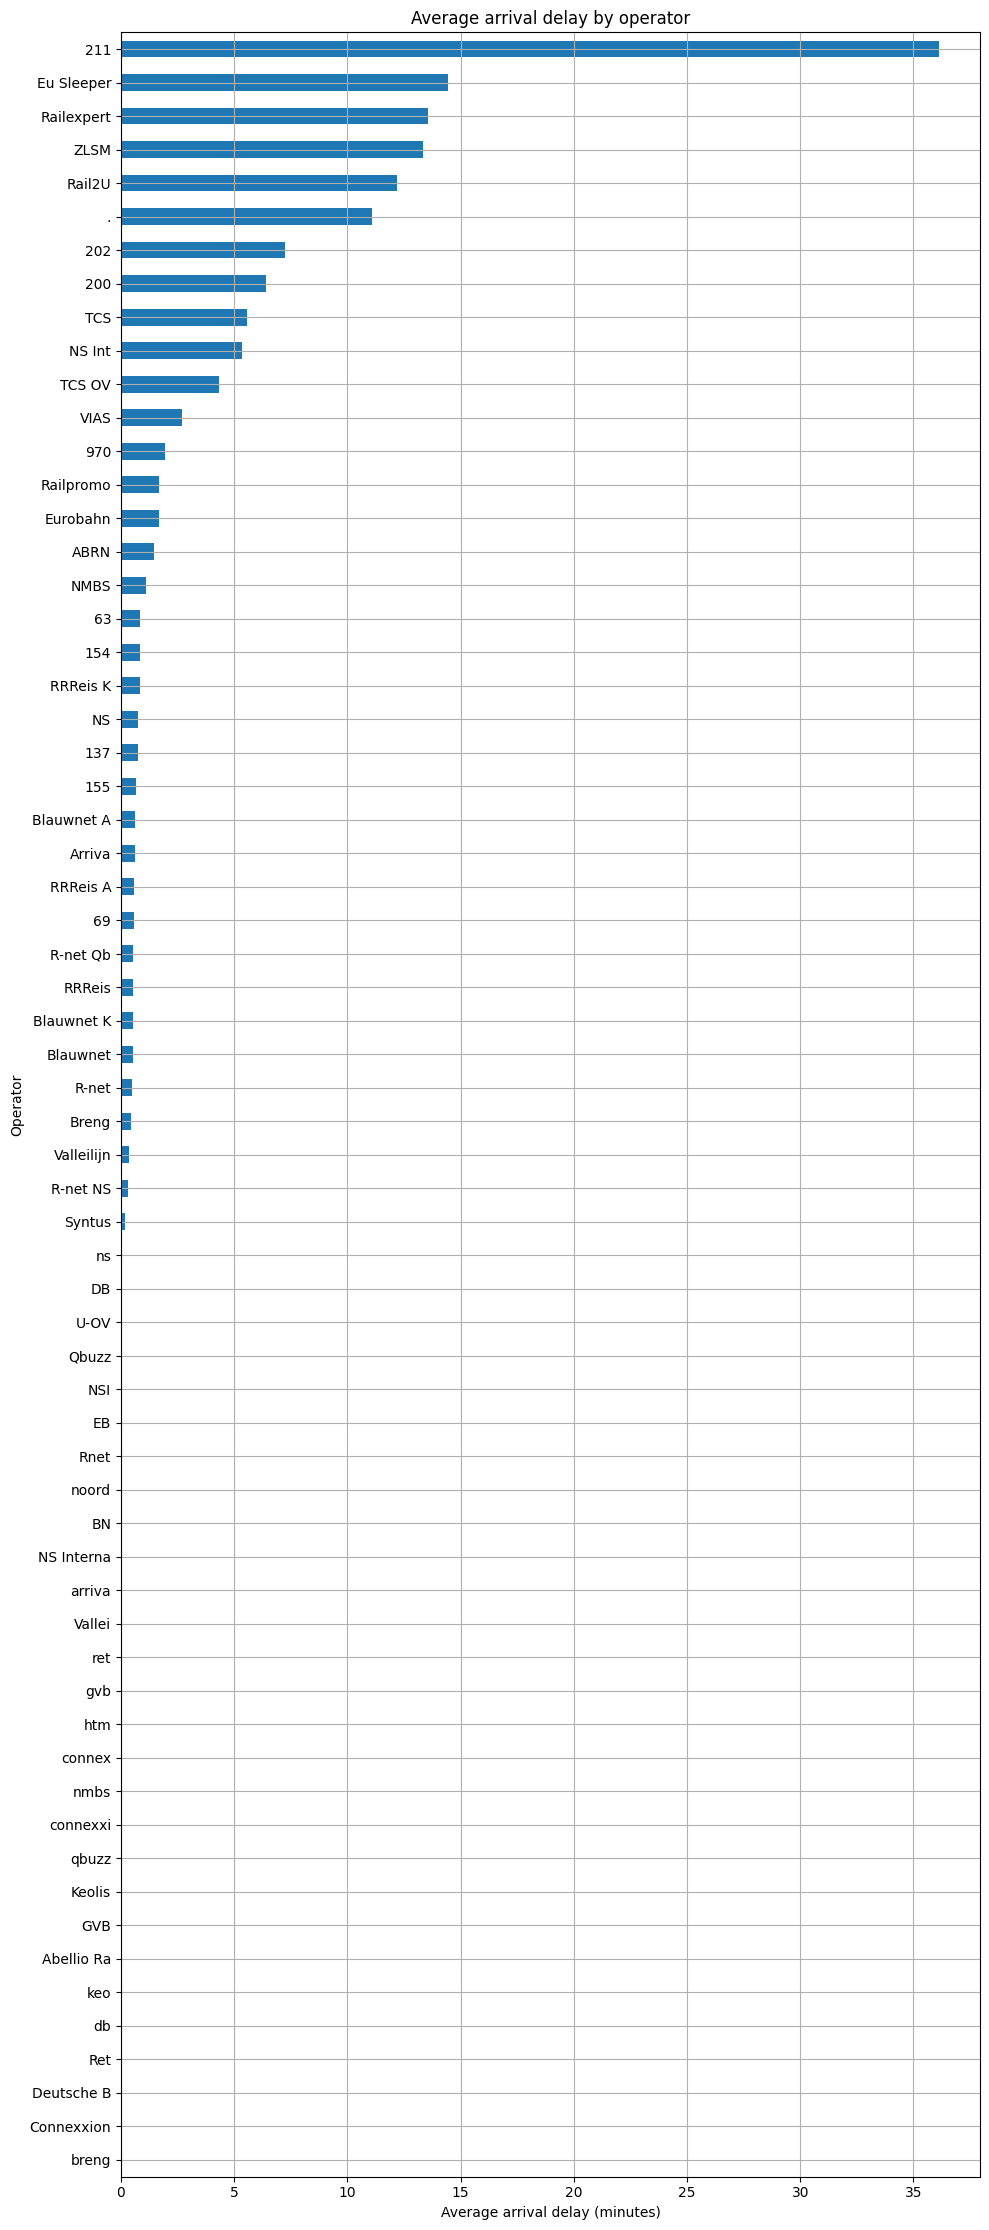

In [18]:
operator_delays = query("""
    SELECT "Service:Company" AS operator,
           avg("Stop:Arrival delay") AS average_delay_minutes
    FROM services
    WHERE "Stop:Arrival time" IS NOT NULL
      AND "Stop:Arrival cancelled" = false
    GROUP BY "Service:Company"
    HAVING count("Stop:Arrival delay") > 0
    ORDER BY average_delay_minutes DESC
""")
display(operator_delays)
ax = operator_delays.plot.barh(
    x="operator", y="average_delay_minutes", legend=False,
    figsize=(10, max(5, len(operator_delays) * 0.35)),
    title="Average arrival delay by operator",
)
ax.invert_yaxis()
ax.set_xlabel("Average arrival delay (minutes)")
ax.set_ylabel("Operator")
plt.tight_layout()
plt.show()

## 7.8. How many services were disrupted in different years? Make a line plot.

,year,disrupted_services
0,2019,1530040
1,2020,1556217
2,2021,1498298
3,2022,1622330
4,2023,1602143
5,2024,1605179
6,2025,1602266


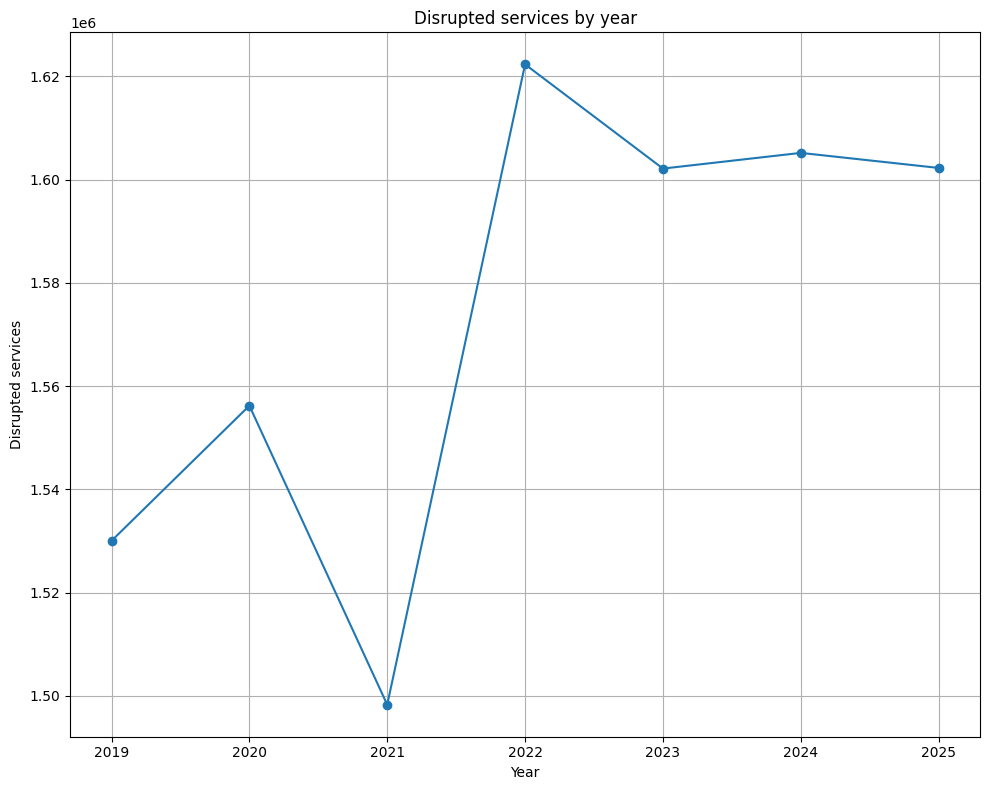

In [23]:
yearly_disruptions = query("""
    SELECT
        YEAR(service_date) AS year,
        COUNT(DISTINCT service_id) FILTER (
            WHERE maximum_delay > 0
            OR completely_cancelled
            OR partly_cancelled
        ) AS disrupted_services
    FROM service_summary
    GROUP BY year
    ORDER BY year
""")
display(yearly_disruptions)
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
ax.plot(yearly_disruptions["year"], yearly_disruptions["disrupted_services"], marker="o")
ax.set(title="Disrupted services by year", xlabel="Year", ylabel="Disrupted services")
ax.set_xticks(yearly_disruptions["year"])
plt.tight_layout()
plt.show()

## 7.9. What fraction of all services were cancelled (Service:Completely cancelled) in different years? Make a line plot.

,year,all_services,cancelled_services,cancelled_fraction
0,2019,2369241,31303,0.013212
1,2020,2453753,212447,0.086580
2,2021,2352676,98253,0.041762
3,2022,2453625,155981,0.063572
4,2023,2323100,135619,0.058378
5,2024,2395636,55360,0.023109
6,2025,2402665,52098,0.021683


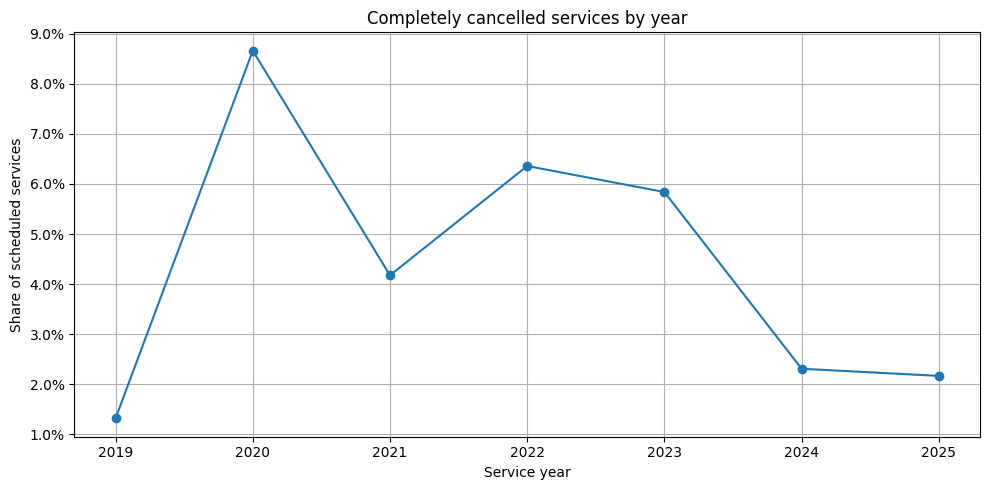

In [24]:
yearly_cancelled = query("""
    SELECT year(service_date) AS year,
           count(*) AS all_services,
           count(*) FILTER (WHERE completely_cancelled) AS cancelled_services,
           count(*) FILTER (WHERE completely_cancelled)::DOUBLE
               / nullif(count(*), 0) AS cancelled_fraction
    FROM service_summary
    GROUP BY year ORDER BY year
""")
display(yearly_cancelled)
fig, ax = plt.subplots()
ax.plot(yearly_cancelled["year"], yearly_cancelled["cancelled_fraction"], marker="o")
ax.set(title="Completely cancelled services by year", xlabel="Service year", ylabel="Share of scheduled services")
ax.set_xticks(yearly_cancelled["year"])
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()

## 8.1. Consecutive stops with LEAD

In [25]:
# Increase db memory limit bc of OOM

db.execute("SET memory_limit = '2GB'")

db.execute("""
    CREATE TABLE service_legs AS
    WITH ordered_stops AS (
        SELECT "Service:RDT-ID", "Stop:RDT-ID" AS stop_id,
               "Stop:Station code" AS start_station_code,
               lead("Stop:Station code") OVER (
                   PARTITION BY "Service:RDT-ID"
                   ORDER BY "Stop:Departure time" NULLS LAST, "Stop:RDT-ID"
               ) AS end_station_code
        FROM services
    )
    SELECT s.*, d.distance
    FROM ordered_stops s
    LEFT JOIN distances_long d
      ON s.start_station_code = d.Station
     AND s.end_station_code = d.other_station
    WHERE s.end_station_code IS NOT NULL
""")
display(query("SELECT * FROM service_legs LIMIT 5"))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Service:RDT-ID,stop_id,start_station_code,end_station_code,distance
0,738915,6220691,GVC,GV,1
1,738915,6220773,GV,DT,8
2,738915,6220922,DT,RTD,14
3,738915,6221185,RTD,BD,50
4,738915,6221909,BD,TB,21


## 8.2. Unique station pairs and route totals

In [26]:
db.execute("""
    CREATE OR REPLACE TABLE station_connections AS
    SELECT
        "Service:RDT-ID",
        start_station_code,
        end_station_code,
        distance
    FROM service_legs
    WHERE start_station_code IS NOT NULL
    AND end_station_code IS NOT NULL
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY
            LEAST(start_station_code, end_station_code),
            GREATEST(start_station_code, end_station_code)
        ORDER BY
            CASE WHEN distance IS NULL THEN 1 ELSE 0 END,
            "Service:RDT-ID",
            stop_id
    ) = 1
""")
db.execute("""
    CREATE TABLE service_lengths AS
    SELECT "Service:RDT-ID", count(*) AS legs,
           count(*) FILTER (WHERE distance IS NULL) AS missing_distances,
           CASE WHEN count(distance) = count(*)
                THEN sum(distance) END AS distance_km
    FROM service_legs
    GROUP BY "Service:RDT-ID"
""")
display(query("SELECT * FROM station_connections LIMIT 5"))
display(query("""
    SELECT count(*) AS unique_pairs,
           count(*) FILTER (WHERE distance IS NULL) AS pairs_without_distance
    FROM station_connections
"""))
display(query("""
    SELECT * FROM service_lengths
    ORDER BY distance_km DESC NULLS LAST LIMIT 10
"""))

print("Sanity check: no duplicated station pairs in station_connections")
display(query("""
    SELECT
        LEAST(start_station_code, end_station_code) AS station_a,
        GREATEST(start_station_code, end_station_code) AS station_b,
        COUNT(*) AS occurrences
    FROM station_connections
    GROUP BY 1, 2
    HAVING COUNT(*) > 1
"""))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Service:RDT-ID,start_station_code,end_station_code,distance
0,11633850,GD,AH,90
1,2763953,HRT,ALM,169
2,8409267,AMFS,GN,169
3,6102935,AML,LLS,102
4,2579956,AML,ODZ,25


,unique_pairs,pairs_without_distance
0,7599,1681


,Service:RDT-ID,legs,missing_distances,distance_km
0,7122512,8,0,2816.0
1,12609771,12,0,2585.0
2,12609957,12,0,2541.0
3,3907188,24,0,2317.0
4,9410486,13,0,2140.0
5,9418567,15,0,2096.0
6,9419772,15,0,2030.0
7,8837442,13,0,1924.0
8,3902549,24,0,1790.0
9,8848652,10,0,1771.0


Sanity check: no duplicated station pairs in station_connections


,station_a,station_b,occurrences


## 8.3. Largest distance between a pair of stations

In [27]:
display(query("""
    SELECT c.start_station_code, a.name_long AS start_station,
           c.end_station_code, b.name_long AS end_station,
           c.distance AS distance_km
    FROM station_connections c
    LEFT JOIN stations a ON c.start_station_code = a.code
    LEFT JOIN stations b ON c.end_station_code = b.code
    WHERE c.distance IS NOT NULL
    QUALIFY c.distance = max(c.distance) OVER ()
    ORDER BY c.start_station_code, c.end_station_code
"""))

,start_station_code,start_station,end_station_code,end_station,distance_km
0,VS,Vlissingen,STV,Stavoren,421


## 8.4. Histogram of inter-station distances

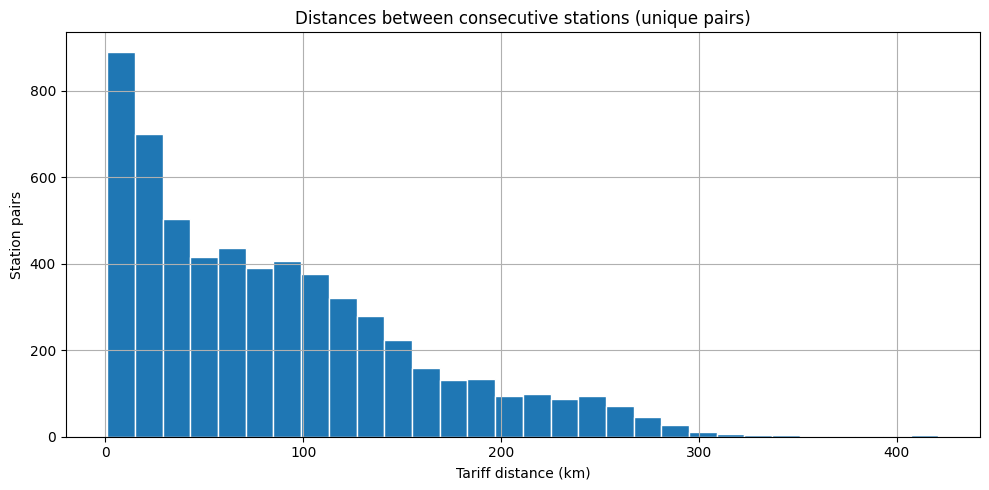

In [28]:
pair_distances = query("""
    SELECT distance FROM station_connections WHERE distance IS NOT NULL
""")
fig, ax = plt.subplots()
ax.hist(pair_distances["distance"], bins=30, edgecolor="white")
ax.set(title="Distances between consecutive stations (unique pairs)",
       xlabel="Tariff distance (km)", ylabel="Station pairs")
plt.tight_layout()
plt.show()

## Stop Docker

```bash
docker stop lab02-homework-postgres
```

It is removed automatically. DuckDB and Parquet stay in `data/homework/`.

In [29]:
subprocess.run([
    "docker", "stop", PG_CONTAINER
], check=True, capture_output=True)

CompletedProcess(args=['docker', 'stop', 'lab02-homework-postgres'], returncode=0, stdout=b'lab02-homework-postgres\n', stderr=b'')